In [1]:
import openseespy.opensees as ops
import numpy as np
import matplotlib.pyplot as plt 
import math 
import opsvis as opsv 
import pandas as pd

In [2]:
E=200*10**9
A=10
I=300*10**-6
nbay=2
hbay=10
wbay=10

In [3]:
ops.wipe()
ops.model('basic','-ndm',2,'-ndf',3)
ops.node(1,0,0)
ops.node(2,0,5)
ops.node(3,10,5)
ops.node(4,10,0)
ops.node(5,0,10)
ops.node(6,10,10)

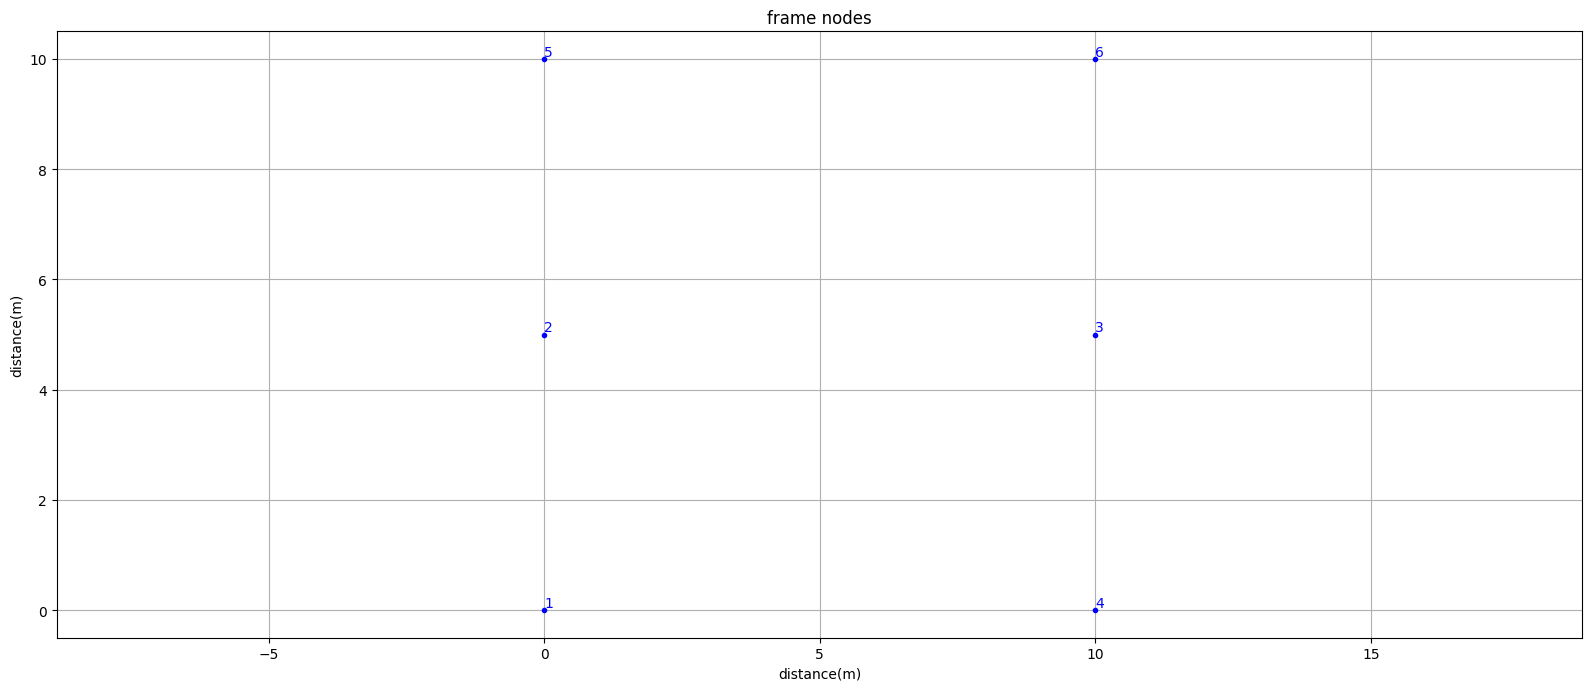

In [4]:
def plotstructure(title):
    opsv.plot_model(fig_wi_he=(50,20))
    plt.title(title)
    plt.xlabel('distance(m)')
    plt.ylabel('distance(m)')
    plt.grid()
    plt.show()
plotstructure('frame nodes')

In [5]:
ops.geomTransf('Linear',1)

In [6]:
ops.element('elasticBeamColumn',12, 1,2, A, E, I,1)
ops.element('elasticBeamColumn',23, 2,3, A, E, I,1)
ops.element('elasticBeamColumn',34, 3,4, A, E, I,1)
ops.element('elasticBeamColumn',25, 2,5, A, E, I,1)
ops.element('elasticBeamColumn',56, 5,6, A, E, I,1)
ops.element('elasticBeamColumn',63, 6,3, A, E, I,1)
ops.fix(1,1,1,1)
ops.fix(4,1,1,1)

In [7]:
ops.mass(2,50,0,0)
ops.mass(3,50,0,0)
ops.mass(5,50,0,0)
ops.mass(6,50,0,0)

In [8]:
ops.equalDOF(2,3,1,2)
ops.equalDOF(5,6,1,2)

In [9]:
# # load defination
# ops.timeSeries('Constant',1)
# ops.pattern('Plain',1,1)
# ops.eleLoad('-ele',23,'-type','-beamUniform',-20000)
# # ops.eleLoad('-ele',24,'-type','-beamUniform',-30000)
# # ops.eleLoad('-ele',25,'-type','-beamUniform',-40000)
# ops.load(2,200000,0.0,0.0)
# ops.load(3,0.0,-50000,0.0)

In [10]:
# analysis
ops.system('BandGen')
ops.numberer('RCM')
ops.constraints('Transformation')
ops.integrator('LoadControl',1)
ops.algorithm('Linear')
ops.analysis('Static')
ops.analyze(1)

0

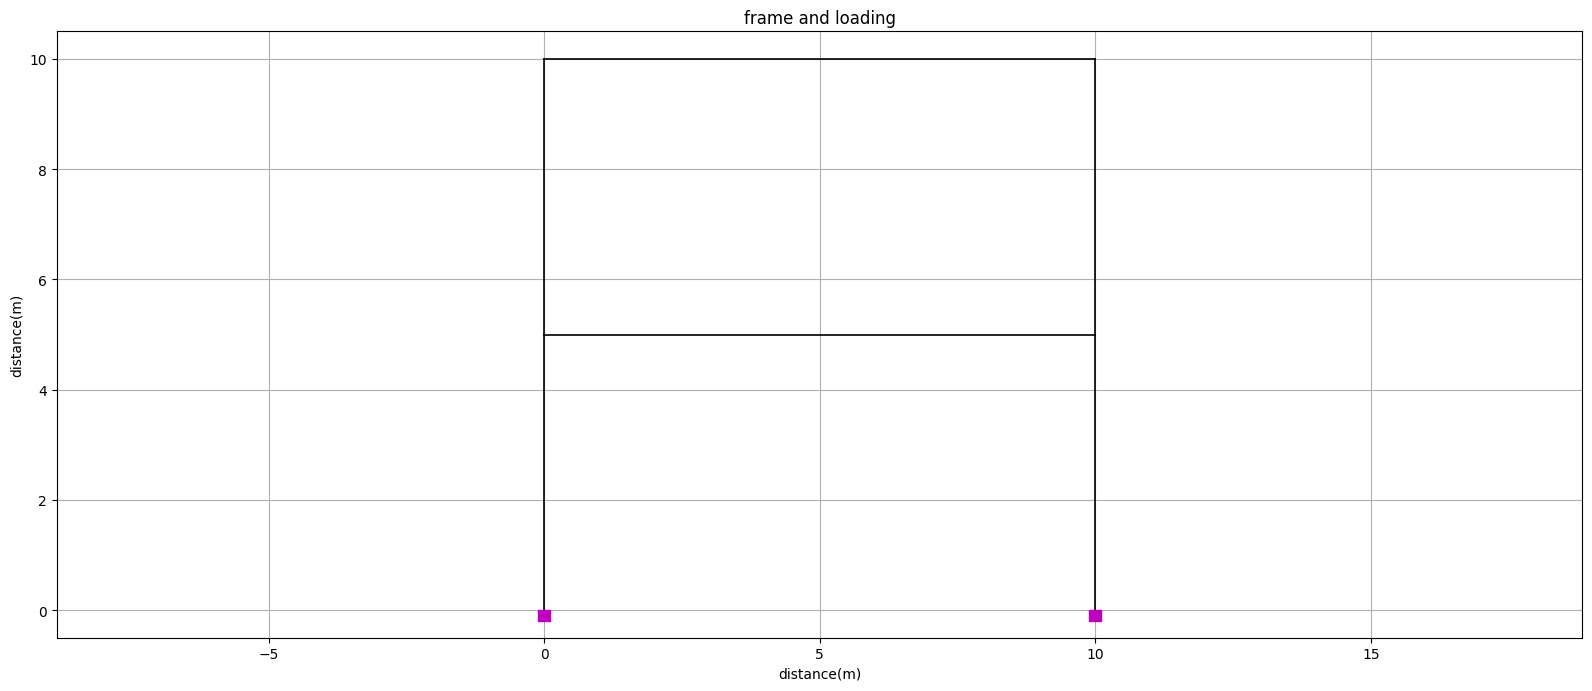

In [11]:
def plotload(title):
    opsv.plot_load(fig_wi_he=(50,20))
    plt.title(title)
    plt.xlabel('distance(m)')
    plt.ylabel('distance(m)')
    plt.grid()
    plt.show()

plotload("frame and loading")

c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:77: RuntimeWarning: divide by zero encountered in scalar divide
  sfac = ratio * dlmax / max_u_abs
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:1239: RuntimeWarning: invalid value encountered in multiply
  crd_xc = xy_c[0, :] + sfac * u_xyc[0, :]
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:1240: RuntimeWarning: invalid value encountered in multiply
  crd_yc = xy_c[1, :] + sfac * u_xyc[1, :]
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:229: RuntimeWarning: invalid value encountered in scalar multiply
  ax.plot([ecrd_nodes[0, 0] + sfac * ed[0, 0],
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:230: RuntimeWarning: invalid value encountered in scalar multiply
  ecrd_eles[0, 0] + sfac * ed[0, 0]] ,
c:\Users\LOQ\AppData\Local\Programs\Python\Pyth

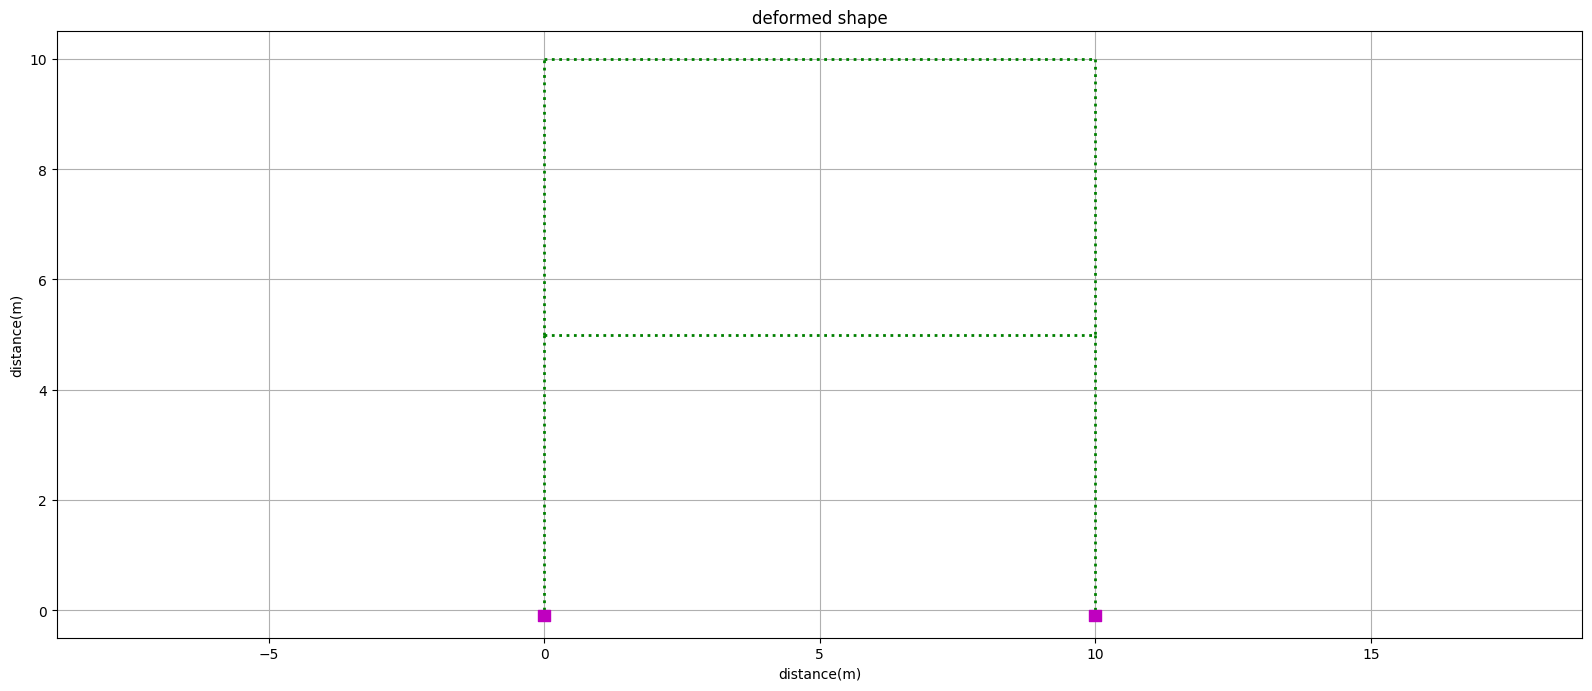

In [12]:
# deflection
s=opsv.plot_defo(fig_wi_he=(50,20),fmt_defo={'color':'red','linestyle':'solid','linewidth':1.5},
                 fmt_undefo={'color': 'green', 'linestyle': ':', 'linewidth': 2})
def shape(title):
    plt.title('deformed shape')
    plt.xlabel('distance(m)')
    plt.ylabel('distance(m)')
    plt.grid()
    plt.show()
shape('deformed shape')

WARNING - the 'fullGenLapack' eigen solver is VERY SLOW. Consider using the default eigen solver.FullGenEigenSolver::solve() - the eigenvalue 3 is numerically undetermined or infinite
FullGenEigenSolver::solve() - the eigenvalue 4 is numerically undetermined or infinite
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:1119: RuntimeWarning: divide by zero encountered in scalar divide
  sfac = ratio * dlmax/max_u_abs
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:1209: RuntimeWarning: invalid value encountered in matmul
  u_l = G @ u
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:1172: RuntimeWarning: invalid value encountered in scalar multiply
  exd = np.array([ecrd[0, 0] + sfac * d[0], ecrd[1, 0] + sfac * d[3]])
c:\Users\LOQ\AppData\Local\Programs\Python\Python312\Lib\site-packages\opsvis\defo.py:1173: RuntimeWarning: invalid value encountered in scalar multiply
  eyd = n

    Time Periods    Frequencies
0   4.909217e-02   2.036985e+01
1   1.368295e-02   7.308367e+01
2  4.686214e-154  2.133919e+153
3  4.686214e-154  2.133919e+153


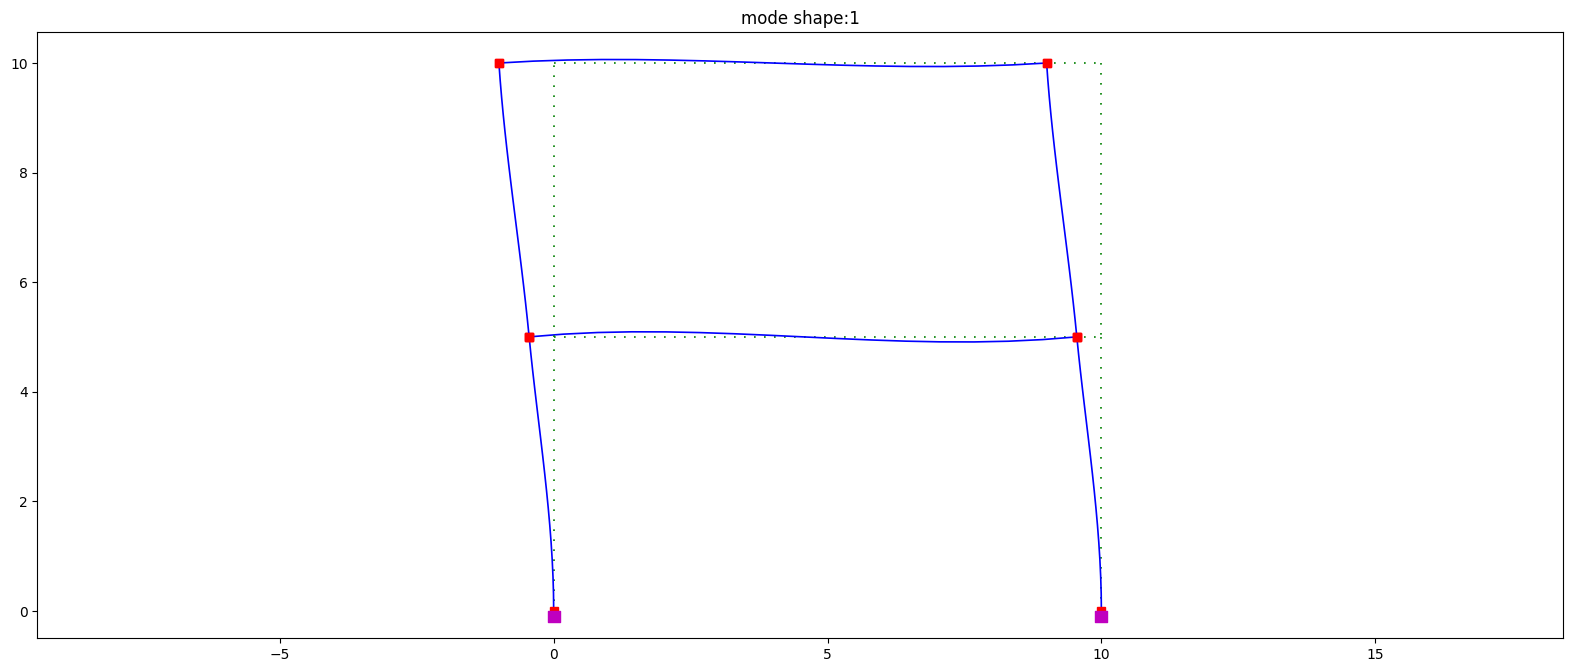

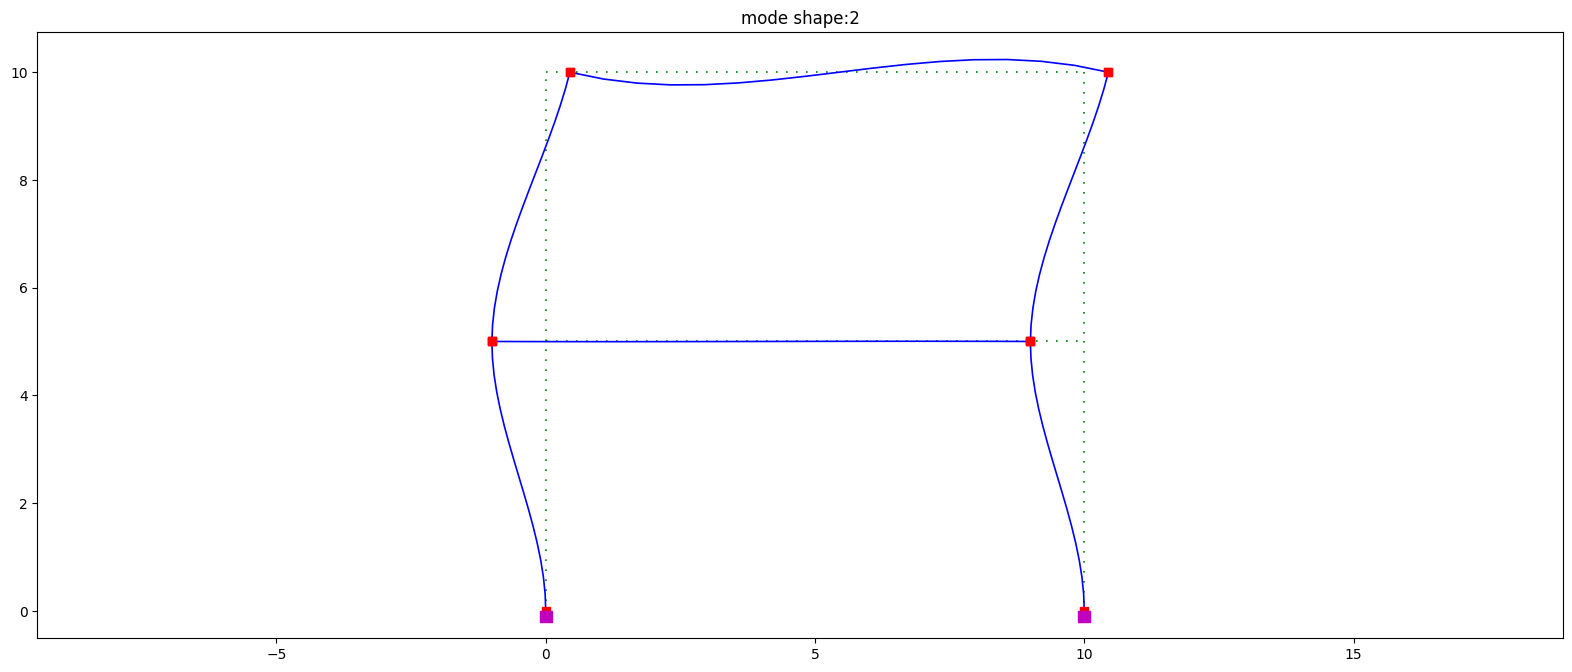

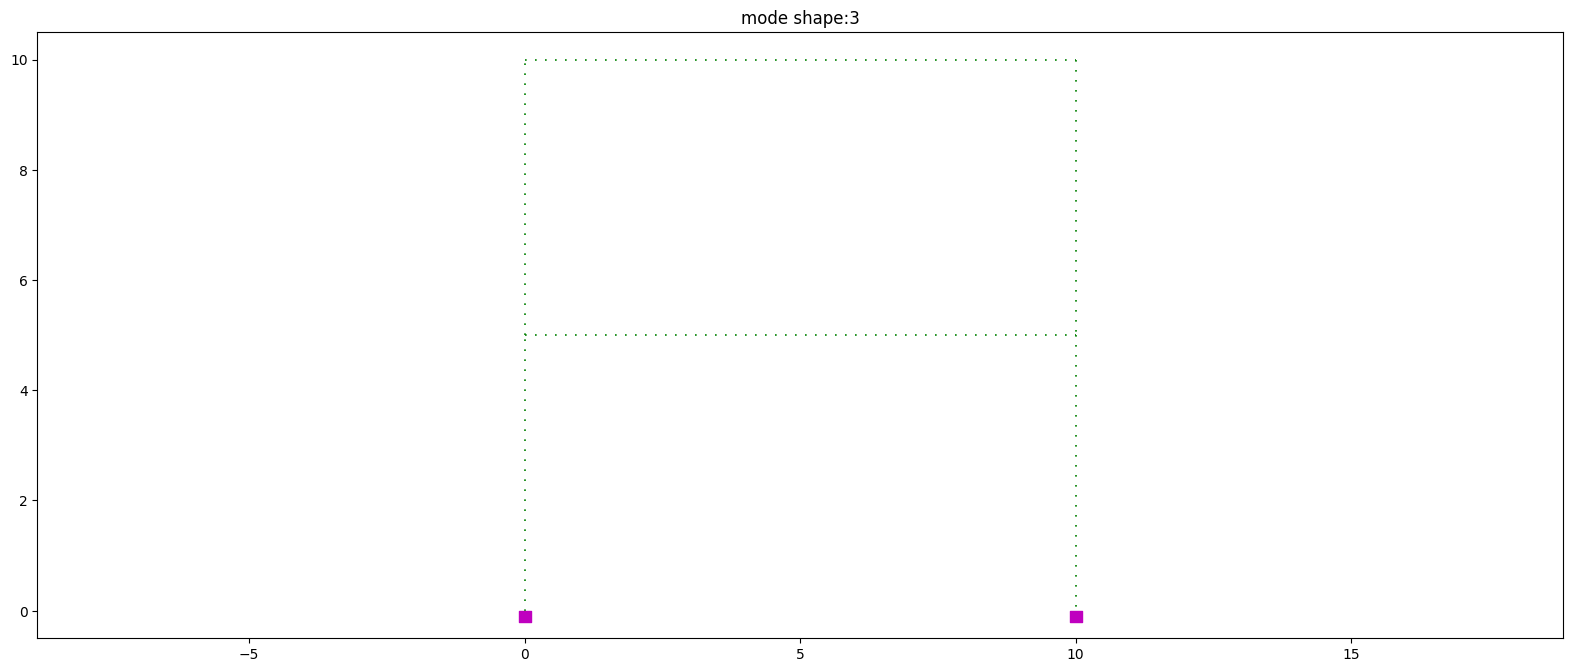

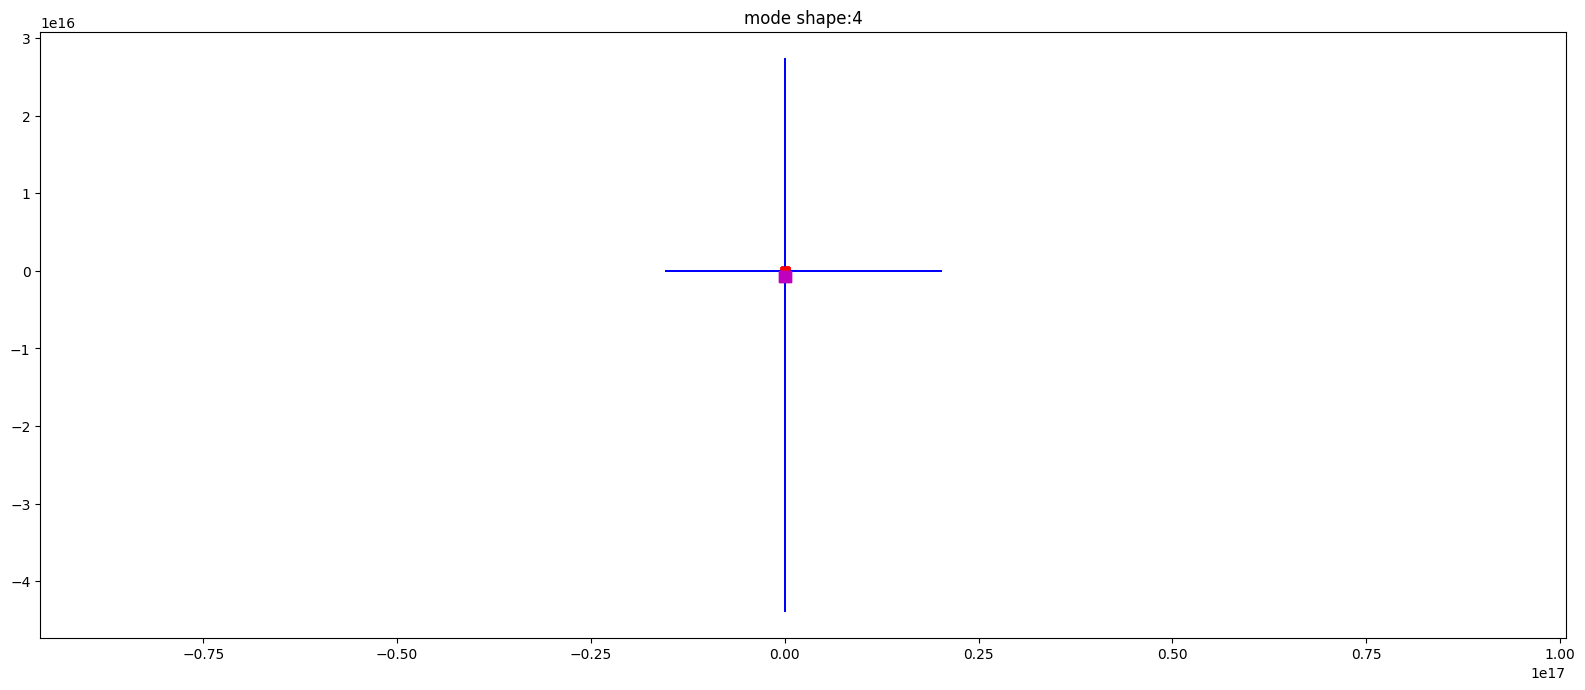

In [13]:

value=ops.eigen('-fullGenLapack',4)
timeperiods=[]
frequency=[]
for i in range(4):
    omega=math.sqrt(value[i])
    timeperi=2*math.pi/omega
    frequencies=1/timeperi
    timeperiods.append(timeperi)
    frequency.append(frequencies)

    opsv.plot_mode_shape(i+1,fig_wi_he=(50,20))
    plt.title('mode shape:'+str(i+1))
data=pd.DataFrame({'Time Periods': timeperiods, 'Frequencies': frequency})
print(data)